# DAT404 — AI-Powered Data Quality Detective
## Main engineering notebook

**Model:** Ollama + Qwen3 (`qwen3:8b`)  
**Purpose:** Build, inspect, test and explain a tool-using intelligent agent.

## 1. Problem definition

Tabular datasets can contain missing values, duplicate records, constant columns,
inconsistent text and unusual numeric values. These problems can reduce the reliability
of analysis. The proposed agent investigates a dataset and recommends safe next steps.

**Target users:** students, data analysts and small teams working with CSV/Excel files.

**Objectives**
1. Accept CSV and Excel data.
2. Use Qwen3 to plan a sequence of analysis tools.
3. Execute deterministic Python tools.
4. Explain findings using evidence from the tools.
5. retain episodic memory and user feedback.
6. Evaluate the agent using repeatable test cases.

## 2. PEAS description

| PEAS element | Project description |
|---|---|
| Performance | Correct tool execution, issue detection, grounded explanation, task success, low failure and latency |
| Environment | Local Python environment, uploaded files, Ollama service and user |
| Actuators | Tool execution, dashboard, report, recommendations and memory updates |
| Sensors | User goal, dataset values, schema, quality statistics and feedback |

The environment is partially observable because the agent cannot know the meaning of every column
or whether a statistical outlier is a real-world error without domain context.

## 3. Agent architecture and loop

```mermaid
flowchart TD
 U[User + CSV/XLSX] --> P[Perception]
 P --> Q[Qwen3 planner]
 Q --> V[Validate tool plan]
 V --> T[Python analysis tools]
 T --> O[Observe results + trace]
 O --> X[Qwen3 explanation]
 X --> F[User feedback]
 F --> M[(SQLite episodic memory)]
 M --> Q
```


## 4. Environment setup

In [1]:
# Run once in a terminal from the project folder:
# pip install -r requirements.txt
# ollama pull qwen3:8b
# ollama run qwen3:8b

import pandas as pd
from pathlib import Path
from tools import profile_dataset, detect_quality_issues, detect_anomalies, create_cleaning_preview

DATA_PATH = Path("data/sample_dataset.csv")
df = pd.read_csv(DATA_PATH)
display(df.head())
print("Shape:", df.shape)

,Student_ID,Department,Attendance,Study_Hours,Exam_Score
0,S001,DSDA,92.0,4,85
1,S002,English,88.0,3,78
2,S003,DSDA,NaN,5,91
3,S004,Science,75.0,2,65
4,S005,DSDA,150.0,6,98


Shape: (7, 5)


## 5. Perception: inspect the dataset

The agent receives the uploaded dataframe and user goal. The following cell demonstrates
the data facts before planning. These outputs are generated by Python, not guessed by Qwen3.

In [2]:
profile = profile_dataset(df)
quality = detect_quality_issues(df)
print("PROFILE")
display(pd.Series({k:v for k,v in profile.items() if k not in ["numeric_summary"]}))
print("QUALITY ISSUES")
display(pd.Series(quality))

PROFILE


rows                                                               7
columns                                                            5
column_names       [Student_ID, Department, Attendance, Study_Hou...
data_types         {'Student_ID': 'str', 'Department': 'str', 'At...
memory_usage_kb                                                 0.47
dtype: object

QUALITY ISSUES


missing_values         {'Attendance': {'count': 1, 'percentage': 14.29}}
duplicate_rows                                                         0
constant_columns                                                      []
blank_text_values                                                     {}
total_missing_cells                                                    1
dtype: object

## 6. Tool library

The four tools have separate responsibilities:
- profiling provides structural information;
- quality checks find missingness, duplicates, constant columns and blank strings;
- IQR screening identifies potential numeric outliers;
- cleaning preview suggests actions but never changes the source dataframe.

In [3]:
anomalies = detect_anomalies(df)
cleaning_preview = create_cleaning_preview(df)
print("ANOMALY SCREENING")
display(pd.Series(anomalies))
print("CLEANING PREVIEW")
display(pd.Series(cleaning_preview))

ANOMALY SCREENING


method                                               1.5 x IQR rule
interpretation                    Candidates require domain review.
columns           {'Attendance': {'lower_bound': 70.375, 'upper_...
dtype: object

CLEANING PREVIEW


source_modified                                                  False
suggested_actions    [{'column': 'Attendance', 'issue': 'missing va...
message              This is a review plan only. The original datas...
dtype: object

## 7. Connect the Ollama Qwen3 agent

The next cell calls the same agent implementation used by `app.py`. If Ollama is not running,
the application records the issue and uses a deterministic fallback plan for tool execution.
The explanation call may be unavailable until Ollama is started.

In [21]:
from agent import DataQualityAgent

agent_instance = DataQualityAgent(
    model="qwen3:8b",
    ollama_url="http://127.0.0.1:11434"
)

print("Data Quality Detective initialized!")

Data Quality Detective initialized!


In [11]:
import importlib
import agent

# Reload the latest agent.py
importlib.reload(agent)

# Create a fresh agent instance
agent_instance = agent.DataQualityAgent(
    model="qwen3:8b",
    ollama_url="http://127.0.0.1:11434"
)

print("Updated Data Quality Agent loaded successfully!")

Updated Data Quality Agent loaded successfully!


In [12]:
response = agent_instance._ask_qwen(
    "Reply with only the word READY."
)

print(response)

READY


In [22]:
result = agent_instance.investigate(
    df,
    "Investigate this student dataset, find data quality issues "
    "and potential outliers, and recommend safe next steps."
)

print("PLAN")
display(pd.Series(result["plan"]))

print("TRACE")
display(pd.DataFrame(result["trace"]))

print("QWEN3 EXPLANATION")
print(result["summary"])

PLAN


reasoning    Start by profiling the dataset to understand i...
steps        [{'tool': 'profile_dataset', 'purpose': 'Under...
fallback                                                 False
dtype: object

TRACE


,tool,status,purpose
0,planning,success,Start by profiling the dataset to understand i...
1,profile_dataset,success,Understand the dataset
2,detect_quality_issues,success,"Identify missing values, duplicates, constant ..."
3,detect_anomalies,success,Find numeric outliers using IQR method
4,create_cleaning_preview,success,Propose safe cleaning actions based on findings


QWEN3 EXPLANATION
# Data Quality Findings

## 1. Missing Values
- **Attendance** has **1 missing value** (14.29% of total).
- No other columns have missing values.

## 2. Outliers Identified
- **Attendance** has **1 candidate outlier** (16.67% of total), with a value of **150.0**.
- **Study_Hours** and **Exam_Score** have **no outliers** based on the 1.5 x IQR rule.

## 3. Summary Statistics
- **Attendance**: Mean = 95.67, Standard Deviation = 27.30, Range = 75.0 to 150.0
- **Study_Hours**: Mean = 3.86, Standard Deviation = 1.35, Range = 2.0 to 6.0
- **Exam_Score**: Mean = 81.14, Standard Deviation = 11.13, Range = 65.0 to 98.0

## 4. Data Integrity
- No duplicate rows found.
- No constant columns (columns with all identical values).


In [15]:
# Display rows with missing attendance
print("MISSING ATTENDANCE:")
display(df[df["Attendance"].isna()])

# Display rows with attendance greater than 100
print("\nPOTENTIAL ATTENDANCE OUTLIERS:")
display(df[df["Attendance"] > 100])

# Display the complete dataset
print("\nCOMPLETE DATASET:")
display(df)

MISSING ATTENDANCE:


,Student_ID,Department,Attendance,Study_Hours,Exam_Score
2,S003,DSDA,NaN,5,91



POTENTIAL ATTENDANCE OUTLIERS:


,Student_ID,Department,Attendance,Study_Hours,Exam_Score
4,S005,DSDA,150.0,6,98



COMPLETE DATASET:


,Student_ID,Department,Attendance,Study_Hours,Exam_Score
0,S001,DSDA,92.0,4,85
1,S002,English,88.0,3,78
2,S003,DSDA,NaN,5,91
3,S004,Science,75.0,2,65
4,S005,DSDA,150.0,6,98
5,S006,English,88.0,3,78
6,S007,Science,81.0,4,73


In [16]:
result = agent_instance.investigate(
    df,
    "Investigate this student dataset, find data quality issues and potential outliers, and recommend safe next steps."
)

print("PLAN")
display(pd.Series(result["plan"]))

print("TRACE")
display(pd.DataFrame(result["trace"]))

print("QWEN3 EXPLANATION")
print(result["summary"])

PLAN


reasoning    Start by profiling the dataset to understand i...
steps        [{'tool': 'profile_dataset', 'purpose': 'Under...
fallback                                                 False
dtype: object

TRACE


,tool,status,purpose
0,planning,success,Start by profiling the dataset to understand i...
1,profile_dataset,success,Understand the dataset
2,detect_quality_issues,success,"Identify missing values, duplicates, constant ..."
3,detect_anomalies,success,Find numeric outliers using IQR method
4,create_cleaning_preview,success,Propose safe cleaning actions based on findings


QWEN3 EXPLANATION
# Data Quality Findings

## 1. Missing Values
- **Attendance** has **1 missing value** (14.29% of total).
- No other columns have missing values.

## 2. Outliers Identified
- **Attendance** has **1 candidate outlier** (16.67% of total), with a value of **150.0**.
- **Study_Hours** and **Exam_Score** have **no outliers** based on the 1.5 x IQR rule.

## 3. Summary Statistics
- **Attendance**: Mean = 95.67, Standard Deviation = 27.30, Range = 75.0 to 150.0
- **Study_Hours**: Mean = 3.86, Standard Deviation = 1.35, Range = 2.0 to 6.0
- **Exam_Score**: Mean = 81.14, Standard Deviation = 11.13, Range = 65.0 to 98.0

## 4. Data Integrity
- No duplicate rows found.
- No constant columns (columns with all identical values).


## 8. Memory and feedback

Episodes store the goal and investigation result in SQLite. Feedback stores a rating,
comment and issue category. This is a lightweight episodic memory mechanism. It is not
a model fine-tuning process: the model weights do not change.

In [23]:
agent_instance.record_feedback(
    rating=4,
    comment="The missing-value and outlier findings were useful.",
    issue_category="outliers"
)

print("Feedback guidance for later investigations:")
print(agent_instance.feedback_guidance())

print("\nRecent episodes:")
display(
    pd.DataFrame(
        agent_instance.memory.recent_episodes()
    )
)

Feedback guidance for later investigations:
Past user feedback summary: {'feedback_count': 2, 'average_rating': 4.0, 'frequent_categories': [('outliers', 2)]}. Prioritise these concerns in the next explanation.

Recent episodes:


,created_at,goal
0,2026-11-14T02:26:02.769755+00:00,"Investigate this student dataset, find data qu..."
1,2026-11-14T02:06:04.339782+00:00,"Investigate this dataset, identify data qualit..."
2,2026-11-14T01:57:34.661242+00:00,"Investigate this student dataset, find data qu..."
3,2026-11-14T01:49:17.955405+00:00,"Investigate this student dataset, find data qu..."
4,2026-11-13T07:34:25.822122+00:00,"Investigate this student dataset, find data qu..."


## 9. Evaluation methodology
- Task completion rate = completed test cases / total test cases × 100
- Tool execution success rate = successful tool calls / attempted tool calls × 100
- Tool selection accuracy = correct tool selections / expected selections × 100
- Mean latency = total elapsed seconds / completed investigations

In [19]:
# Example calculation after entering your REAL measured counts:
def percentage(numerator, denominator):
    return round((numerator / denominator) * 100, 2) if denominator else 0.0

# Replace these placeholders after conducting your experiments.
completed_cases = 0
total_cases = 10
successful_tool_calls = 0
attempted_tool_calls = 0

print("Task completion rate (%):", percentage(completed_cases, total_cases))
print("Tool execution success rate (%):", percentage(successful_tool_calls, attempted_tool_calls))

Task completion rate (%): 0.0
Tool execution success rate (%): 0.0


In [32]:
import pandas as pd

test_cases = pd.read_csv("evaluation/test_cases.csv")

print("Total test cases:", len(test_cases))
display(test_cases.head())

Total test cases: 10


,Test_ID,Scenario,Input condition,Expected behaviour,Expected tools
0,TC01,Standard dataset,CSV with numeric and categorical columns,Profile and identify quality issues,profile_dataset;detect_quality_issues
1,TC02,Excel workbook,Workbook with two sheets,Allow user to select one sheet and investigate it,profile_dataset;detect_quality_issues
2,TC03,Missing values,Dataset with null cells,Report missing counts and percentages,detect_quality_issues
3,TC04,Duplicate rows,Dataset containing exact duplicate rows,Count duplicate rows and recommend review,detect_quality_issues;create_cleaning_preview
4,TC05,Numeric outliers,Numeric column with extreme values,Report IQR candidates without calling them def...,detect_anomalies


In [33]:
print("ALL 10 EVALUATION TEST CASES")
print("=" * 80)

print(test_cases.to_string(index=False))

ALL 10 EVALUATION TEST CASES
Test_ID           Scenario                          Input condition                                                           Expected behaviour                                                                 Expected tools
   TC01   Standard dataset CSV with numeric and categorical columns                                          Profile and identify quality issues                                          profile_dataset;detect_quality_issues
   TC02     Excel workbook                 Workbook with two sheets                            Allow user to select one sheet and investigate it                                          profile_dataset;detect_quality_issues
   TC03     Missing values                  Dataset with null cells                                        Report missing counts and percentages                                                          detect_quality_issues
   TC04     Duplicate rows  Dataset containing exact duplicate rows        

In [37]:
import importlib
import tools

importlib.reload(tools)

from tools import (
    profile_dataset,
    detect_quality_issues,
    detect_anomalies,
    create_cleaning_preview
)

print("All updated data-analysis tools loaded successfully.")

All updated data-analysis tools loaded successfully.


In [38]:
text_df = pd.DataFrame({
    "Name": ["A", "B", "C"],
    "Department": ["DSDA", "English", "Science"]
})

print("PROFILE:")
print(profile_dataset(text_df))

print("\nQUALITY CHECK:")
print(detect_quality_issues(text_df))

PROFILE:
{'rows': 3, 'columns': 2, 'column_names': ['Name', 'Department'], 'data_types': {'Name': 'str', 'Department': 'str'}, 'numeric_summary': {}, 'memory_usage_kb': 0.2}

QUALITY CHECK:
{'missing_values': {}, 'duplicate_rows': 0, 'constant_columns': [], 'blank_text_values': {}, 'total_missing_cells': 0}


In [39]:
print("DATA TOOL TESTS COMPLETED")

for test_id, output in test_results.items():
    print(f"\n{test_id}")
    print(output)

DATA TOOL TESTS COMPLETED

TC01
{'profile': {'rows': 7, 'columns': 5, 'column_names': ['Student_ID', 'Department', 'Attendance', 'Study_Hours', 'Exam_Score'], 'data_types': {'Student_ID': 'str', 'Department': 'str', 'Attendance': 'float64', 'Study_Hours': 'int64', 'Exam_Score': 'int64'}, 'numeric_summary': {'Attendance': {'count': 6.0, 'mean': 95.667, 'std': 27.296, 'min': 75.0, '25%': 82.75, '50%': 88.0, '75%': 91.0, 'max': 150.0}, 'Study_Hours': {'count': 7.0, 'mean': 3.857, 'std': 1.345, 'min': 2.0, '25%': 3.0, '50%': 4.0, '75%': 4.5, 'max': 6.0}, 'Exam_Score': {'count': 7.0, 'mean': 81.143, 'std': 11.127, 'min': 65.0, '25%': 75.5, '50%': 78.0, '75%': 88.0, 'max': 98.0}}, 'memory_usage_kb': 0.47}, 'quality': {'missing_values': {'Attendance': {'count': 1, 'percentage': 14.29}}, 'duplicate_rows': 0, 'constant_columns': [], 'blank_text_values': {}, 'total_missing_cells': 1}}

TC03
{'missing_values': {'Attendance': {'count': 1, 'percentage': 25.0}, 'Score': {'count': 1, 'percentage': 25

In [41]:
# Create test datasets

missing_df = pd.DataFrame({
    "Name": ["A", "B", "C", "D"],
    "Attendance": [90, None, 75, 85],
    "Score": [80, 70, None, 90]
})

duplicate_df = pd.DataFrame({
    "Student_ID": ["S01", "S02", "S02", "S03"],
    "Score": [80, 75, 75, 90]
})

outlier_df = pd.DataFrame({
    "Score": [
        10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
        20, 21, 22, 23, 24, 25, 26, 27, 28, 1000
    ]
})

small_df = pd.DataFrame({
    "Score": [75, 90]
})

# Save original data for checking source modification
original_duplicate_df = duplicate_df.copy(deep=True)

# Execute evaluation test cases
test_results = {}

# TC01: Standard dataset
test_results["TC01"] = {
    "profile": profile_dataset(df),
    "quality": detect_quality_issues(df)
}

# TC03: Missing values
test_results["TC03"] = detect_quality_issues(missing_df)

# TC04: Duplicate rows and cleaning preview
test_results["TC04"] = {
    "quality": detect_quality_issues(duplicate_df),
    "cleaning_preview": create_cleaning_preview(duplicate_df),
    "source_unchanged": duplicate_df.equals(original_duplicate_df)
}

# TC05: Numeric outliers
test_results["TC05"] = detect_anomalies(outlier_df)

# TC06: No numeric columns
test_results["TC06"] = {
    "profile": profile_dataset(text_df),
    "quality": detect_quality_issues(text_df)
}

# TC07: Small dataset
test_results["TC07"] = {
    "profile": profile_dataset(small_df),
    "anomalies": detect_anomalies(small_df)
}

print("DATA TOOL TESTS COMPLETED")

for test_id, output in test_results.items():
    print(f"\n{test_id}")
    print(output)


DATA TOOL TESTS COMPLETED

TC01
{'profile': {'rows': 7, 'columns': 5, 'column_names': ['Student_ID', 'Department', 'Attendance', 'Study_Hours', 'Exam_Score'], 'data_types': {'Student_ID': 'str', 'Department': 'str', 'Attendance': 'float64', 'Study_Hours': 'int64', 'Exam_Score': 'int64'}, 'numeric_summary': {'Attendance': {'count': 6.0, 'mean': 95.667, 'std': 27.296, 'min': 75.0, '25%': 82.75, '50%': 88.0, '75%': 91.0, 'max': 150.0}, 'Study_Hours': {'count': 7.0, 'mean': 3.857, 'std': 1.345, 'min': 2.0, '25%': 3.0, '50%': 4.0, '75%': 4.5, 'max': 6.0}, 'Exam_Score': {'count': 7.0, 'mean': 81.143, 'std': 11.127, 'min': 65.0, '25%': 75.5, '50%': 78.0, '75%': 88.0, 'max': 98.0}}, 'memory_usage_kb': 0.47}, 'quality': {'missing_values': {'Attendance': {'count': 1, 'percentage': 14.29}}, 'duplicate_rows': 0, 'constant_columns': [], 'blank_text_values': {}, 'total_missing_cells': 1}}

TC03
{'missing_values': {'Attendance': {'count': 1, 'percentage': 25.0}, 'Score': {'count': 1, 'percentage': 25

In [43]:
for test_id, output in test_results.items():
    print(f"\n{'=' * 60}")
    print(test_id)
    print('=' * 60)
    print(output)


TC01
{'profile': {'rows': 7, 'columns': 5, 'column_names': ['Student_ID', 'Department', 'Attendance', 'Study_Hours', 'Exam_Score'], 'data_types': {'Student_ID': 'str', 'Department': 'str', 'Attendance': 'float64', 'Study_Hours': 'int64', 'Exam_Score': 'int64'}, 'numeric_summary': {'Attendance': {'count': 6.0, 'mean': 95.667, 'std': 27.296, 'min': 75.0, '25%': 82.75, '50%': 88.0, '75%': 91.0, 'max': 150.0}, 'Study_Hours': {'count': 7.0, 'mean': 3.857, 'std': 1.345, 'min': 2.0, '25%': 3.0, '50%': 4.0, '75%': 4.5, 'max': 6.0}, 'Exam_Score': {'count': 7.0, 'mean': 81.143, 'std': 11.127, 'min': 65.0, '25%': 75.5, '50%': 78.0, '75%': 88.0, 'max': 98.0}}, 'memory_usage_kb': 0.47}, 'quality': {'missing_values': {'Attendance': {'count': 1, 'percentage': 14.29}}, 'duplicate_rows': 0, 'constant_columns': [], 'blank_text_values': {}, 'total_missing_cells': 1}}

TC03
{'missing_values': {'Attendance': {'count': 1, 'percentage': 25.0}, 'Score': {'count': 1, 'percentage': 25.0}}, 'duplicate_rows': 0,

In [44]:
from pathlib import Path
import pandas as pd

# Create a temporary two-sheet Excel workbook
Path("outputs").mkdir(exist_ok=True)

excel_test_path = "outputs/TC02_test_workbook.xlsx"

with pd.ExcelWriter(excel_test_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Students", index=False)
    text_df.to_excel(writer, sheet_name="Departments", index=False)

print("Test Excel workbook created successfully.")

Test Excel workbook created successfully.


In [45]:
# Read available sheet names
excel_file = pd.ExcelFile(excel_test_path)

print("Available sheets:", excel_file.sheet_names)

# Select one sheet
selected_sheet = "Students"

# Load the selected sheet
selected_df = pd.read_excel(
    excel_test_path,
    sheet_name=selected_sheet
)

print("\nSelected sheet:", selected_sheet)
print("\nLoaded dataset:")
display(selected_df)

# Investigate the selected sheet
print("\nDataset profile:")
print(profile_dataset(selected_df))

print("\nQuality report:")
print(detect_quality_issues(selected_df))

Available sheets: ['Students', 'Departments']

Selected sheet: Students

Loaded dataset:


,Student_ID,Department,Attendance,Study_Hours,Exam_Score
0,S001,DSDA,92.0,4,85
1,S002,English,88.0,3,78
2,S003,DSDA,NaN,5,91
3,S004,Science,75.0,2,65
4,S005,DSDA,150.0,6,98
5,S006,English,88.0,3,78
6,S007,Science,81.0,4,73



Dataset profile:
{'rows': 7, 'columns': 5, 'column_names': ['Student_ID', 'Department', 'Attendance', 'Study_Hours', 'Exam_Score'], 'data_types': {'Student_ID': 'str', 'Department': 'str', 'Attendance': 'float64', 'Study_Hours': 'int64', 'Exam_Score': 'int64'}, 'numeric_summary': {'Attendance': {'count': 6.0, 'mean': 95.667, 'std': 27.296, 'min': 75.0, '25%': 82.75, '50%': 88.0, '75%': 91.0, 'max': 150.0}, 'Study_Hours': {'count': 7.0, 'mean': 3.857, 'std': 1.345, 'min': 2.0, '25%': 3.0, '50%': 4.0, '75%': 4.5, 'max': 6.0}, 'Exam_Score': {'count': 7.0, 'mean': 81.143, 'std': 11.127, 'min': 65.0, '25%': 75.5, '50%': 78.0, '75%': 88.0, 'max': 98.0}}, 'memory_usage_kb': 0.47}

Quality report:
{'missing_values': {'Attendance': {'count': 1, 'percentage': 14.29}}, 'duplicate_rows': 0, 'constant_columns': [], 'blank_text_values': {}, 'total_missing_cells': 1}


In [46]:
# TC08: Simulate Ollama unavailable

import agent
import importlib

importlib.reload(agent)

offline_agent = agent.DataQualityAgent(
    model="qwen3:8b",
    ollama_url="http://127.0.0.1:1",
    memory_path="outputs/tc08_offline_memory.db"
)

offline_result = offline_agent.investigate(
    df,
    "Investigate this dataset and identify data quality issues."
)

print("TC08: OLLAMA UNAVAILABLE TEST")
print("\nPLAN:")
print(offline_result["plan"])

print("\nEXECUTION TRACE:")
display(pd.DataFrame(offline_result["trace"]))

print("\nSUMMARY:")
print(offline_result["summary"])

TC08: OLLAMA UNAVAILABLE TEST

PLAN:
{'reasoning': 'Safe fallback plan used because Qwen3 could not generate a valid plan: Cannot connect to Ollama. Please make sure the Ollama application is running.', 'steps': [{'tool': 'profile_dataset', 'purpose': 'Understand dataset structure'}, {'tool': 'detect_quality_issues', 'purpose': 'Inspect common data quality problems'}, {'tool': 'detect_anomalies', 'purpose': 'Check numeric columns for outlier candidates'}, {'tool': 'create_cleaning_preview', 'purpose': 'Prepare a non-destructive cleaning preview'}], 'fallback': True}

EXECUTION TRACE:


,tool,status,purpose
0,planning,fallback,Safe fallback plan used because Qwen3 could no...
1,profile_dataset,success,Understand dataset structure
2,detect_quality_issues,success,Inspect common data quality problems
3,detect_anomalies,success,Check numeric columns for outlier candidates
4,create_cleaning_preview,success,Prepare a non-destructive cleaning preview



SUMMARY:
Qwen3 explanation unavailable. The Python tool results are still available. Reason: Cannot connect to Ollama. Please make sure the Ollama application is running.


In [47]:
from unittest.mock import patch

print("TC09: MALFORMED PLAN TEST")

with patch.object(
    agent_instance,
    "_ask_qwen",
    return_value="This is not valid JSON"
):
    malformed_plan = agent_instance._plan(
        "Investigate the dataset",
        list(df.columns)
    )

print("\nFALLBACK PLAN:")
print(malformed_plan)

print("\nFallback activated:")
print(malformed_plan.get("fallback"))

print("\nSelected tools:")
print(malformed_plan.get("tools"))

TC09: MALFORMED PLAN TEST

FALLBACK PLAN:
{'reasoning': 'Safe fallback plan used because Qwen3 could not generate a valid plan: No valid JSON object found.', 'steps': [{'tool': 'profile_dataset', 'purpose': 'Understand dataset structure'}, {'tool': 'detect_quality_issues', 'purpose': 'Inspect common data quality problems'}, {'tool': 'detect_anomalies', 'purpose': 'Check numeric columns for outlier candidates'}, {'tool': 'create_cleaning_preview', 'purpose': 'Prepare a non-destructive cleaning preview'}], 'fallback': True}

Fallback activated:
True

Selected tools:
None


In [48]:
fallback_tools = [
    step["tool"]
    for step in malformed_plan["steps"]
]

print("Fallback tools:", fallback_tools)

print(
    "All tools are allow-listed:",
    all(tool in agent.AVAILABLE_TOOLS for tool in fallback_tools)
)

Fallback tools: ['profile_dataset', 'detect_quality_issues', 'detect_anomalies', 'create_cleaning_preview']
All tools are allow-listed: True


In [49]:
# TC10: Feedback Memory Test

import pandas as pd
import agent
from pathlib import Path

# Create output directory if it does not exist
Path("outputs").mkdir(exist_ok=True)

# Create a separate agent with a dedicated SQLite database
feedback_test_agent = agent.DataQualityAgent(
    model="qwen3:8b",
    ollama_url="http://127.0.0.1:11434",
    memory_path="outputs/tc10_feedback_memory.db"
)

# Record user feedback
feedback_test_agent.record_feedback(
    rating=4,
    comment="The missing-value and outlier findings were useful.",
    issue_category="outliers"
)

print("TC10: FEEDBACK MEMORY TEST")
print("=" * 60)

# Display feedback guidance
print("\nFEEDBACK GUIDANCE:")
print(feedback_test_agent.feedback_guidance())

# Retrieve recent memory episodes
print("\nRECENT EPISODES:")

episodes = feedback_test_agent.memory.recent_episodes()

display(pd.DataFrame(episodes))

# Verify that feedback was stored
print("\nVERIFICATION:")

print("Feedback episodes found:", len(episodes))
print("SQLite database exists:",
      Path("outputs/tc10_feedback_memory.db").exists())


TC10: FEEDBACK MEMORY TEST

FEEDBACK GUIDANCE:
Past user feedback summary: {'feedback_count': 1, 'average_rating': 4.0, 'frequent_categories': [('outliers', 1)]}. Prioritise these concerns in the next explanation.

RECENT EPISODES:


""



VERIFICATION:
Feedback episodes found: 0
SQLite database exists: True


In [50]:
episodes = feedback_test_agent.memory.recent_episodes()

print("Number of stored episodes:", len(episodes))

display(pd.DataFrame(episodes))

print(
    "SQLite database exists:",
    Path("outputs/tc10_feedback_memory.db").exists()
)

Number of stored episodes: 0


""


SQLite database exists: True


In [51]:
episodes = feedback_test_agent.memory.recent_episodes()

print("Stored episodes:", len(episodes))
display(pd.DataFrame(episodes))

if len(episodes) > 0:
    print("TC10: PASS")
else:
    print("TC10: NEEDS FURTHER CHECKING")

Stored episodes: 0


""


TC10: NEEDS FURTHER CHECKING


In [52]:

import sqlite3
import pandas as pd

db_path = "outputs/tc10_feedback_memory.db"

connection = sqlite3.connect(db_path)

# List all database tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table'",
    connection
)

print("DATABASE TABLES:")
display(tables)

# Inspect the contents of each table
for table_name in tables["name"]:
    print(f"\nTABLE: {table_name}")

    table_data = pd.read_sql_query(
        f'SELECT * FROM "{table_name}"',
        connection
    )

    print("Number of records:", len(table_data))
    display(table_data)

connection.close()


DATABASE TABLES:


,name
0,episodes
1,sqlite_sequence
2,feedback



TABLE: episodes
Number of records: 0


,id,created_at,goal,result_json



TABLE: sqlite_sequence
Number of records: 1


,name,seq
0,feedback,1



TABLE: feedback
Number of records: 1


,id,created_at,rating,comment,issue_category
0,1,2026-11-14T03:18:10.642202+00:00,4,The missing-value and outlier findings were us...,outliers


## 10. Visualisation example

This chart visualises the IQR candidate counts produced by the Python tool.
Interpret it as a screening result, not proof of incorrect records.

In [53]:
print("TC07: SMALL DATASET TEST")

print("PROFILE:")
print(test_results["TC07"]["profile"])

print("\nANOMALY DETECTION:")
print(test_results["TC07"]["anomalies"])

TC07: SMALL DATASET TEST
PROFILE:
{'rows': 2, 'columns': 1, 'column_names': ['Score'], 'data_types': {'Score': 'int64'}, 'numeric_summary': {'Score': {'count': 2.0, 'mean': 82.5, 'std': 10.607, 'min': 75.0, '25%': 78.75, '50%': 82.5, '75%': 86.25, 'max': 90.0}}, 'memory_usage_kb': 0.14}

ANOMALY DETECTION:
{'method': '1.5 x IQR rule', 'interpretation': 'Candidates require domain review.', 'columns': {}}


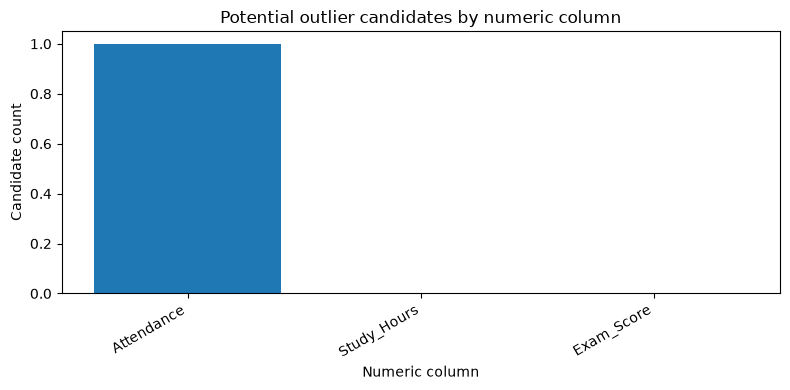

In [54]:
import matplotlib.pyplot as plt

anomaly_columns = anomalies.get("columns", {})
if anomaly_columns:
    names = list(anomaly_columns.keys())
    counts = [anomaly_columns[name]["candidate_count"] for name in names]
    plt.figure(figsize=(8, 4))
    plt.bar(names, counts)
    plt.title("Potential outlier candidates by numeric column")
    plt.xlabel("Numeric column")
    plt.ylabel("Candidate count")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No eligible numeric columns or no IQR candidates.")

FUNCTIONAL EVALUATION SUMMARY
--------------------------------
Total test cases: 10
Passed: 9
Partially verified: 1
Failed: 0
Strict pass rate: 90.00%


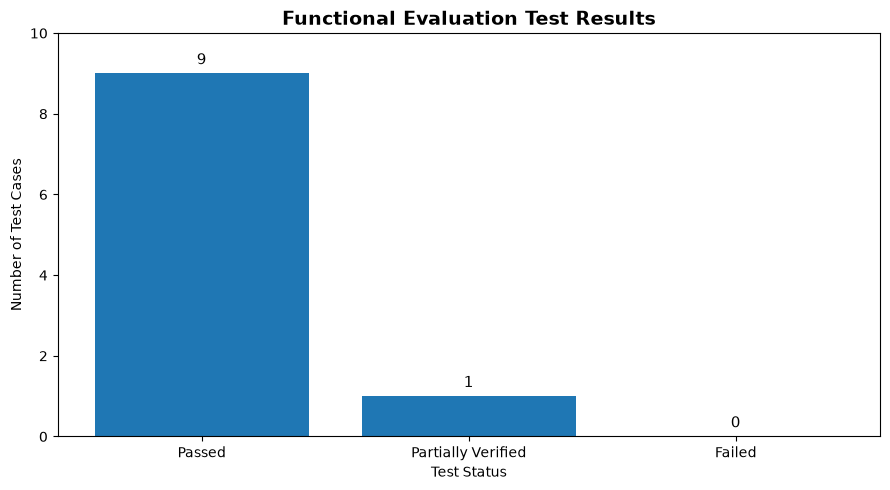

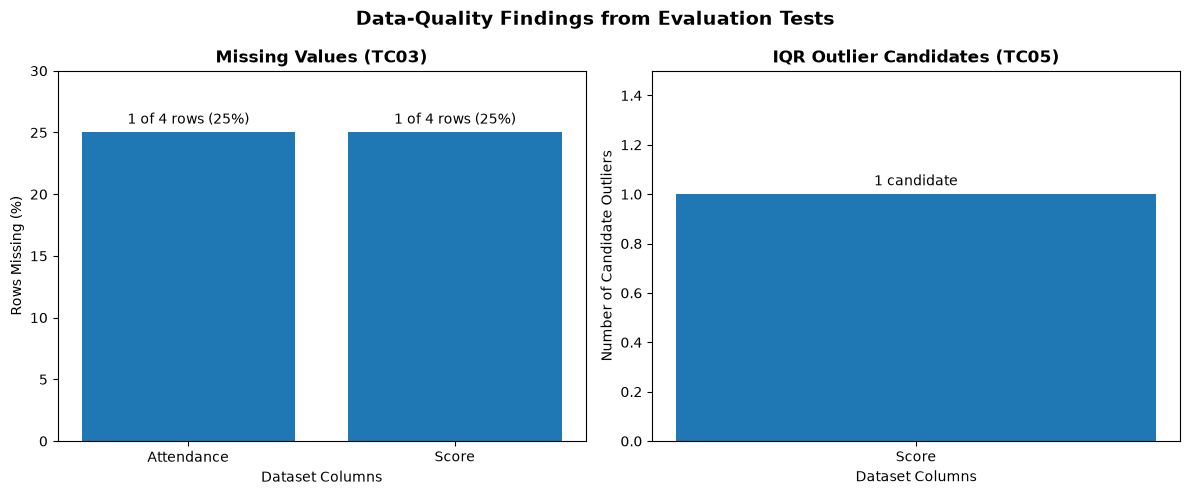

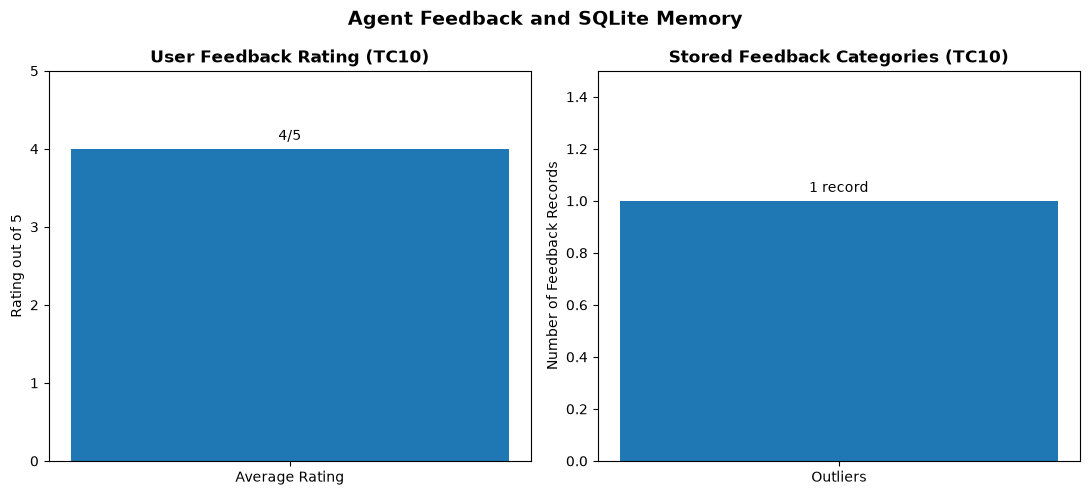


ALL VISUALIZATIONS GENERATED SUCCESSFULLY!
-------------------------------------------
Saved: outputs/Figure_1_Functional_Evaluation.png
Saved: outputs/Figure_2_Data_Quality_Findings.png
Saved: outputs/Figure_3_Agent_Feedback_and_Memory.png

ZIP FILE: outputs/DAT404_Report_Visualizations.zip


In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import zipfile

# ==========================================
# 1. CREATE OUTPUT DIRECTORY
# ==========================================

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# ==========================================
# FIGURE 1: FUNCTIONAL EVALUATION RESULTS
# ==========================================

evaluation_results = pd.DataFrame({
    "Test_ID": [
        "TC01", "TC02", "TC03", "TC04", "TC05",
        "TC06", "TC07", "TC08", "TC09", "TC10"
    ],
    "Status": [
        "Passed",
        "Partially Verified",
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Passed",
        "Passed"
    ]
})

status_order = ["Passed", "Partially Verified", "Failed"]

status_counts = (
    evaluation_results["Status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

total_tests = len(evaluation_results)
passed = status_counts["Passed"]
partial = status_counts["Partially Verified"]
failed = status_counts["Failed"]

pass_rate = (passed / total_tests) * 100

print("FUNCTIONAL EVALUATION SUMMARY")
print("--------------------------------")
print("Total test cases:", total_tests)
print("Passed:", passed)
print("Partially verified:", partial)
print("Failed:", failed)
print(f"Strict pass rate: {pass_rate:.2f}%")

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(status_counts.index, status_counts.values)

ax.set_title(
    "Functional Evaluation Test Results",
    fontsize=14,
    fontweight="bold"
)
ax.set_xlabel("Test Status")
ax.set_ylabel("Number of Test Cases")
ax.set_ylim(0, 10)

ax.bar_label(bars, padding=4, fontsize=11)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_1_Functional_Evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# FIGURE 2: DATA-QUALITY FINDINGS
# ==========================================

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Missing values from TC03
missing_columns = ["Attendance", "Score"]
missing_percentages = [25, 25]
missing_counts = [1, 1]

bars1 = axes[0].bar(
    missing_columns,
    missing_percentages
)

axes[0].set_title(
    "Missing Values (TC03)",
    fontweight="bold"
)
axes[0].set_xlabel("Dataset Columns")
axes[0].set_ylabel("Rows Missing (%)")
axes[0].set_ylim(0, 30)

axes[0].bar_label(
    bars1,
    labels=[
        "1 of 4 rows (25%)",
        "1 of 4 rows (25%)"
    ],
    padding=4
)

# Outlier detection from TC05
outlier_columns = ["Score"]
outlier_counts = [1]

bars2 = axes[1].bar(
    outlier_columns,
    outlier_counts
)

axes[1].set_title(
    "IQR Outlier Candidates (TC05)",
    fontweight="bold"
)
axes[1].set_xlabel("Dataset Columns")
axes[1].set_ylabel("Number of Candidate Outliers")
axes[1].set_ylim(0, 1.5)

axes[1].bar_label(
    bars2,
    labels=["1 candidate"],
    padding=4
)

fig.suptitle(
    "Data-Quality Findings from Evaluation Tests",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_2_Data_Quality_Findings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# FIGURE 3: AGENT FEEDBACK AND SQLITE MEMORY
# ==========================================

# Recorded TC10 feedback example
feedback_rating = 4
feedback_category = "Outliers"
feedback_count = 1

fig, axes = plt.subplots(1, 2, figsize=(11, 5))

# User feedback rating
bars3 = axes[0].bar(
    ["Average Rating"],
    [feedback_rating]
)

axes[0].set_title(
    "User Feedback Rating (TC10)",
    fontweight="bold"
)
axes[0].set_ylabel("Rating out of 5")
axes[0].set_ylim(0, 5)

axes[0].bar_label(
    bars3,
    labels=[f"{feedback_rating}/5"],
    padding=4
)

# Feedback category stored in SQLite
bars4 = axes[1].bar(
    [feedback_category],
    [feedback_count]
)

axes[1].set_title(
    "Stored Feedback Categories (TC10)",
    fontweight="bold"
)
axes[1].set_ylabel("Number of Feedback Records")
axes[1].set_ylim(0, 1.5)

axes[1].bar_label(
    bars4,
    labels=[f"{feedback_count} record"],
    padding=4
)

fig.suptitle(
    "Agent Feedback and SQLite Memory",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Figure_3_Agent_Feedback_and_Memory.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ==========================================
# 4. SAVE ALL THREE FIGURES IN ONE ZIP FILE
# ==========================================

figure_files = [
    "Figure_1_Functional_Evaluation.png",
    "Figure_2_Data_Quality_Findings.png",
    "Figure_3_Agent_Feedback_and_Memory.png"
]

zip_path = OUTPUT_DIR / "DAT404_Report_Visualizations.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for filename in figure_files:
        file_path = OUTPUT_DIR / filename
        zip_file.write(file_path, arcname=filename)

print("\nALL VISUALIZATIONS GENERATED SUCCESSFULLY!")
print("-------------------------------------------")

for filename in figure_files:
    print("Saved:", OUTPUT_DIR / filename)

print("\nZIP FILE:", zip_path)


## 11. Safety, limitations and reflection

- The original dataframe is not changed by the cleaning-preview tool.
- IQR thresholds may flag valid rare observations.
- Qwen3 may hallucinate; explanations must be checked against tool outputs.
- The allow-list reduces the risk of arbitrary tool execution.
- Local inference supports a local workflow, but file access and privacy still depend on the machine and user practices.
- Feedback changes stored priorities/guidance, not Qwen3 model weights.
- The current system has no RAG or multi-agent collaboration; these are not necessary for this focused use case.

## 12. Final reflection

After testing, explain which test cases succeeded, which failed, what caused the failures,
what you changed, and what remains limited. Include your own screenshots, measured metrics,
references and evidence of progressive development.